# Estudo Prático: Transformada de Fourier

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread
import os
from ipywidgets import interact, IntSlider, Dropdown

plt.rcParams.update({
    'figure.figsize': (10, 3.5),
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

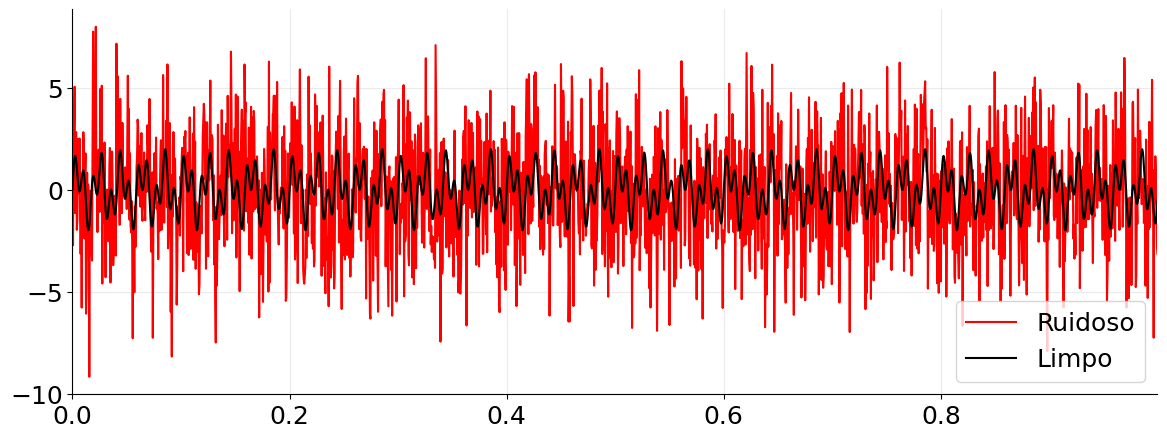

In [27]:
plt.rcParams['figure.figsize'] = [14, 5]
plt.rcParams.update({'font.size': 18})

# Cria um sinal sintético com duas frequências: 120Hz e 50Hz
dt = 0.0005                                      # Espaçamento temporal utilizado
t = np.arange(0,1,dt)                            # Vetor tempo
f = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*120*t) # Soma das senoides com as frequências citadas
f_limpo = f                                      # Armazenamos o sinal limpo
f = f + 2.5*np.random.randn(len(t))              # Adiona ruído ao sinal anterior

# Ploting
plt.plot(t, f, color='r', linewidth=1.5, label='Ruidoso')
plt.plot(t, f_limpo, color='k', linewidth=1.5, label='Limpo')
plt.xlim(t[0],t[-1])
plt.legend()
plt.show()

Acima, simplesmente criamos um conjunto de dados artificial: um sinal limpo, em preto, formado pela soma de duas senoides, ao qual acrescentamos um sinal ruidoso de grande amplitude. Agora vamos fazer um exercício de faz de conta: imaginar que o sinal preto não existe, que não sabemos que ele está embutido no sinal vermelho, e que só temos acesso ao sinal ruidoso. Sabemos apenas que o sinal vermelho contém vários artefatos que atrapalham a nossa análise. Assim, vamos tentar encontrar as frequências significativas e filtrar as demais.

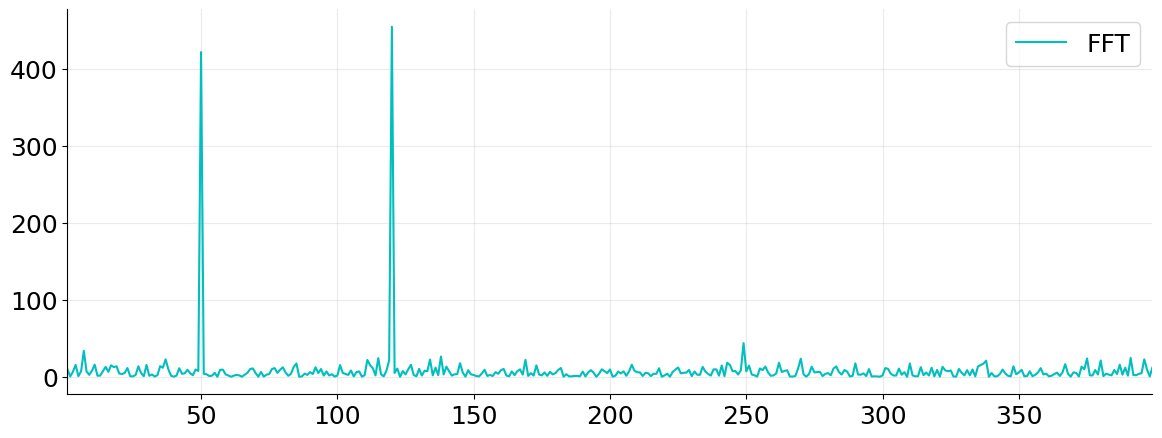

In [28]:
n = len(t)
fhat = np.fft.fft(f,n)                     # Computa a FFT
DEP = fhat * np.conj(fhat) / n             # Espectro de potência (potÇencia por freq)
freq = (1/(dt*n)) * np.arange(n)           # Cria um eixo de frequências, a partir do eixo temporal
L = np.arange(1,np.floor(n/5),dtype='int') # Plota apenas as primeiras frequências

# Ploting
plt.plot(freq[L], DEP[L], color='c', linewidth=1.5, label='FFT')
plt.xlim(freq[L[0]], freq[L[-1]])
plt.legend()
plt.show()

No domínio da frequência, fica bem evidente que duas frequências concentram a maior parte da potência do sinal, e todo o resto pode ser considerado ruído. Então vamos filtrar o sinal de um jeito bem simples: basta escolher um valor limite (threshold) para a potência. Se o valor de uma componente ficar abaixo desse limite, o espectro correspondente é zerado; caso contrário, ele é mantido. Pela análise do gráfico, um valor em torno de 200 já resolve:

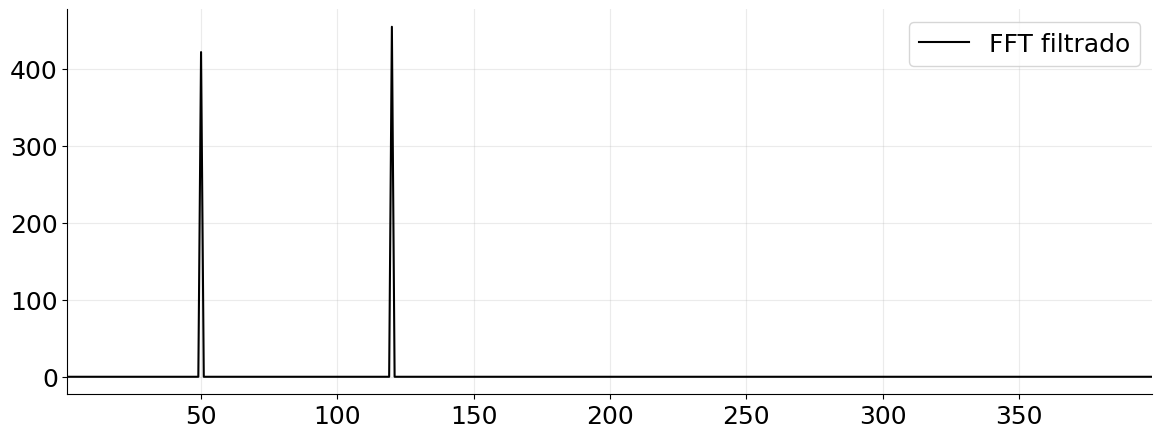

In [29]:

## Usando a potência para filtrar o ruído
indices = DEP > 200       # Encontra as potências maiores que o threshold
DEPlimpo = DEP * indices  # Zera todos os outros indices

# Ploting
plt.plot(freq[L], DEPlimpo[L], color='k', linewidth=1.5, label='FFT filtrado')
plt.xlim(freq[L[0]], freq[L[-1]])
plt.legend()
plt.show()

Agora podemos usar FFT para obter o sinal original:

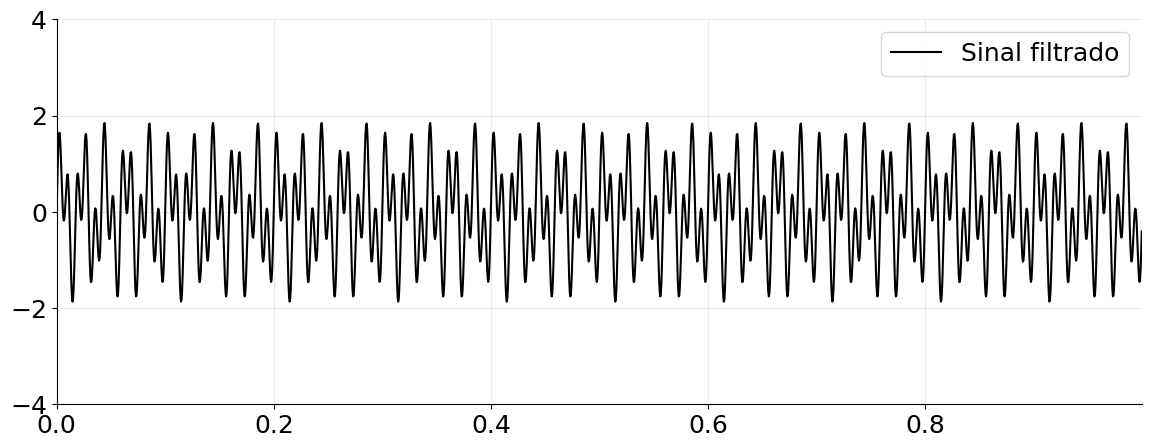

In [30]:
fhat_filtrado = indices * fhat     # Zera todos os coeficientes da transformada de fourier
ffilt = np.fft.ifft(fhat_filtrado) # FFT inversa para o sinal filtrado
# Ploting
plt.plot(t, ffilt, color='k', linewidth=1.5, label='Sinal filtrado')
plt.xlim(t[0], t[-1])
plt.ylim(-4, 4)
plt.legend()
plt.show()

### A "Receita" de um Sinal: Tempo -> Frequência

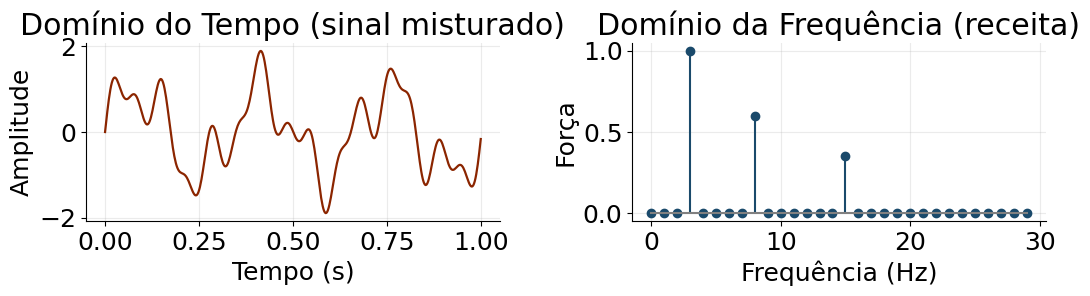

In [31]:
fs = 500
t = np.linspace(0, 1, fs, endpoint=False)

# Mistura ("vitamina") de 3 ingredientes puros: 3 Hz, 8 Hz e 15 Hz
sinal = 1.0 * np.sin(2*np.pi*3*t) + 0.6 * np.sin(2*np.pi*8*t) + 0.35 * np.sin(2*np.pi*15*t)

freqs = np.fft.rfftfreq(len(t), d=1/fs)
amps = 2 * np.abs(np.fft.rfft(sinal)) / len(t)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.3))
ax1.plot(t, sinal, color='#8b2500', lw=1.6)
ax1.set(title='Domínio do Tempo (sinal misturado)', xlabel='Tempo (s)', ylabel='Amplitude')
ax2.stem(freqs[:30], amps[:30], linefmt='#1a4a6b', markerfmt='o', basefmt='gray')
ax2.set(title='Domínio da Frequência (receita)', xlabel='Frequência (Hz)', ylabel='Força')
plt.tight_layout()
plt.show()

Aqui conseguimos vizualizar o domínio do tempo e frequência lada a lado. Os dois gráficos têm a mesma informação, só vista de ângulos diferentes. Como a janela tem exatamente 1 s e as frequências são inteiras, cada senoide completa um número inteiro de ciclos dentro dela. Assim a FFT não sofre spectral leakage (vazamento espectral). Com uma frequência como 3,5 Hz, o pico se espalharia pelas frequências vizinhas. Vale testar isso trocando o 8 por 8.5 e vendo o que acontece.

### Girar o Sinal ao Redor do Círculo (Sonda de Fourier)

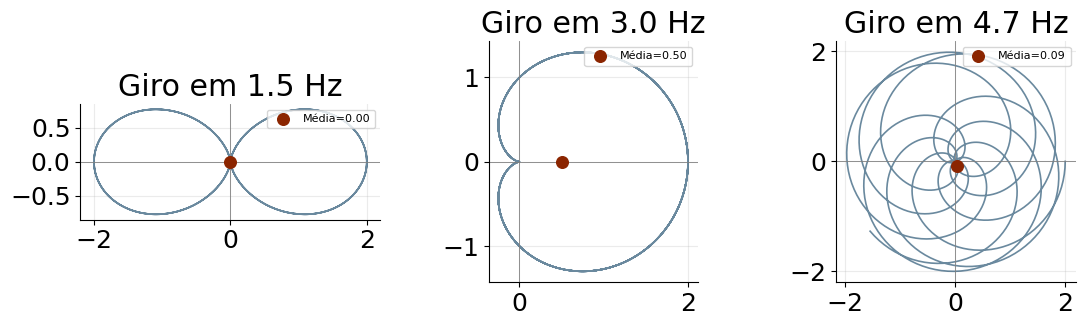

In [32]:
t_wrap = np.linspace(0, 2, 1000, endpoint=False)
# Sinal de teste em 3.0 Hz deslocado para cima (+1) para ficar fácil visualizar o giro
x = 1.0 + np.cos(2 * np.pi * 3.0 * t_wrap)

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6))
for ax, f_giro in zip(axes, [1.5, 3.0, 4.7]):
    z = x * np.exp(-1j * 2 * np.pi * f_giro * t_wrap)
    centro = z.mean()
    ax.plot(z.real, z.imag, color='#1a4a6b', alpha=0.65, lw=1.2)
    ax.scatter([centro.real], [centro.imag], color='#8b2500', s=70, zorder=5, label=f'Média={abs(centro):.2f}')
    ax.axhline(0, color='gray', lw=0.6); ax.axvline(0, color='gray', lw=0.6)
    ax.set_aspect('equal')
    ax.set_title(f'Giro em {f_giro} Hz')
    ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

Esse é o mecanismo por dentro da Transformada de Fourier: enrolar o sinal em volta da origem a uma certa velocidade de giro e ver onde fica o centro de massa da figura. O sinal de teste é x = 1 + cos(2π·3·t): uma cosseno de 3 Hz deslocada para cima em 1. Depois, para cada frequência de giro f_giro, ele calcula z = x · e^(-j2π·f_giro·t). Isso pega o valor do sinal em cada instante e o coloca como um ponto no plano complexo, girando no sentido horário a f_giro voltas por segundo. O valor de x define a distância até a origem, e o tempo define o ângulo. Por fim, z.mean() calcula o centro de massa da curva.

### Onda Quadrada via Soma de Ciclos Ímpares

Agora vamos ao caminho inverso: em vez de decompor um sinal em ingredientes, você monta um sinal somando senoides. E o resultado é uma onda quadrada feita só de curvas suaves. A série de Fourier de uma onda quadrada é: y(t) = (4/π) · Σ sin(2π(2m+1)·t) / (2m+1)

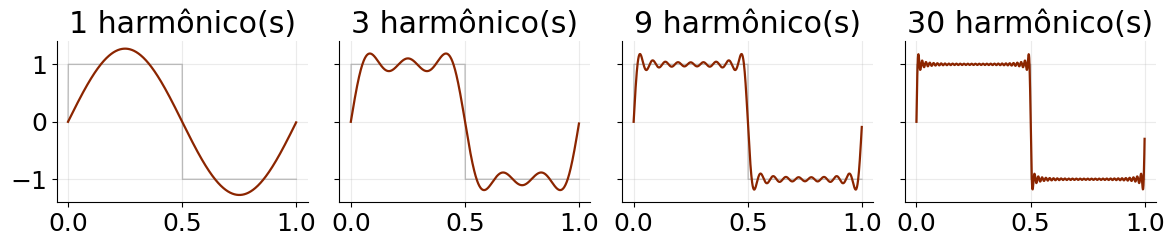

In [33]:
tq = np.linspace(0, 1, 800, endpoint=False)
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, K in zip(axes, [1, 3, 9, 30]):
    y = sum((4 / np.pi) * np.sin(2 * np.pi * (2*m + 1) * tq) / (2*m + 1) for m in range(K))
    ax.plot(tq, np.sign(np.sin(2*np.pi*tq)), color='gray', alpha=0.45, lw=1)
    ax.plot(tq, y, color='#8b2500', lw=1.6)
    ax.set_title(f'{K} harmônico(s)')
plt.tight_layout()
plt.show()

Só entram os harmônicos ímpares (1, 3, 5, 7, ...), e cada um tem amplitude 1/(2m+1). O range(K) define quantos termos entram na soma. Em cada gráfico podemos ver:

- 1 harmônico: só a fundamental, uma senoide de 1 Hz. Ela já sobe e desce no ritmo certo, mas passa de 1.0 porque a amplitude 4/π ≈ 1.27 é maior que a da onda quadrada.
- 3 harmônicos: entram 1, 3 e 5 Hz. Aparecem ondulações no topo e na base, e as quinas começam a ficar mais retas.
- 9 harmônicos: os platôs ficam bem planos, com ondulações pequenas e rápidas, e a transição no meio fica íngreme.
- 30 harmônicos: quase uma onda quadrada, mas com um detalhe importante nas bordas.

Se aplicassemos a FFT nessa onda quadrada, veriamos picos só nas frequências ímpares (1, 3, 5, ...), com alturas decaindo como 4/(π·n). É a mesma “receita” do primeiro exemplo, só que agora com infinitos ingredientes, e cada vez que você adiciona um, a figura se aproxima do alvo.

### Epiciclos 2D: Decompondo um Contorno Complexo

Agora vamos tirar a série de Fourier da reta levá-la ao plano: o sinal é uma curva fechada z = x + iy, e cada ingrediente da receita vira um círculo girando (epiciclo). Somar círculos encadeados desenha o contorno.

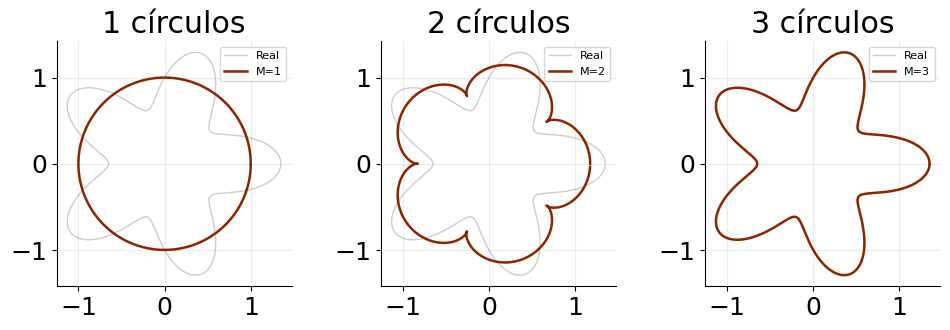

In [34]:
u = np.linspace(0, 2*np.pi, 360, endpoint=False)
# Contorno fechado paramétrico em z = x + i*y (formato de estrela)
r = 1.0 + 0.35 * np.cos(5 * u)
z_contorno = r * np.exp(1j * u)

C = np.fft.fft(z_contorno) / len(z_contorno)
ks = np.fft.fftfreq(len(z_contorno), d=1/len(z_contorno))
ordem = np.argsort(-np.abs(C))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, M in zip(axes, [1, 2, 3]):
    z_rec = sum(C[idx] * np.exp(1j * ks[idx] * u) for idx in ordem[:M])
    ax.plot(z_contorno.real, z_contorno.imag, color='gray', alpha=0.4, lw=1, label='Real')
    ax.plot(z_rec.real, z_rec.imag, color='#8b2500', lw=1.8, label=f'M={M}')
    ax.set_aspect('equal'); ax.set_title(f'{M} círculos'); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Aqui o fft é complexo, uma curva no plano é um sinal complexo, então frequências negativas (círculos girando no sentido horário) carregam informação própria e não são espelho das positivas. Com dois circulos já temos uma estrela aproximada, mas com bicos e cantos errados. Já com 3 círculos chegamos ao contorno real, e a linha cinza some por baixo da vermelha.

### As Imagens

Bom, visto tudo isso, chegou a hora de dizer que a transformada de Fourier também pode ser aplicada a imagens. É possível defini-la em 2 dimensões, e no próprio NumPy a implementação é dada por np.fft.fft2. Vale dizer que não estamos fazendo nada muito novo: basta aplicar a transformação em todas as colunas e depois em todas as linhas, ou vice-versa (não importa qual direção seja transformada primeiro). Vejamos o código a seguir:

(np.float64(-0.5), np.float64(3023.5), np.float64(2461.5), np.float64(-0.5))

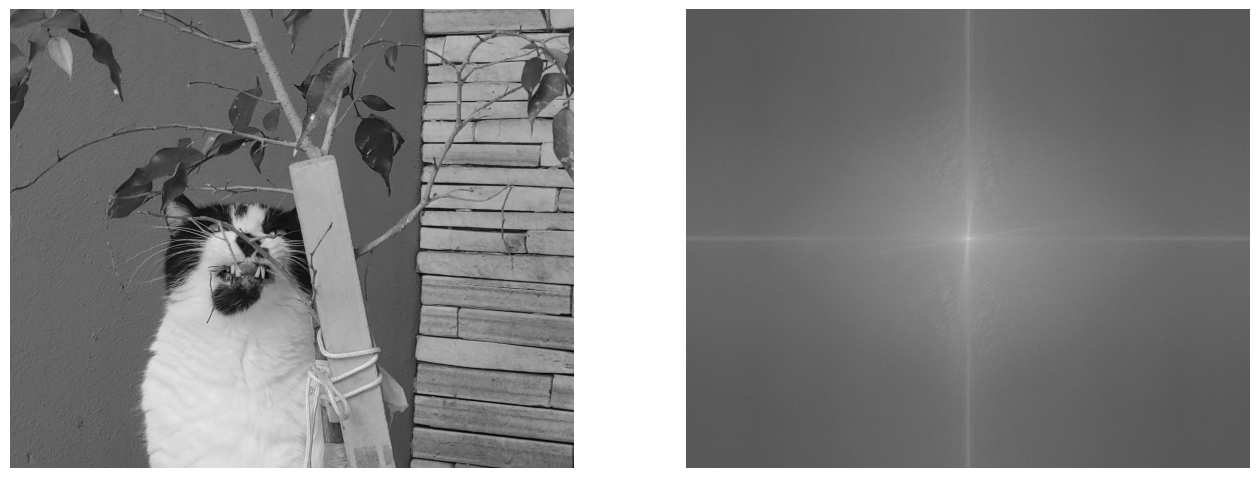

In [35]:

plt.rcParams['figure.figsize'] = [16, 15]
plt.rcParams.update({'font.size': 18})

path = 'bento.jpg'

A = imread(path)
B = np.mean(A, -1); # Converte para escala de cinza

fig,axs = plt.subplots(1,2)

# Plot da imagem
img = axs[0].imshow(B)
img.set_cmap('gray')
axs[0].axis('off')

# Computando a fft2 do gatinho
D = np.fft.fft2(B)

# Plot da imagem, usamos escala log pois alguns pixels 
# tem valor extremamente pequenos
img = axs[1].imshow(np.fft.fftshift(np.log(np.abs(D))))
img.set_cmap('gray')
axs[1].axis('off')

Como podem ver, esta é uma imagem do Bento, uma imagem é um sinal 2D, e a Transformada de Fourier 2D decompõe essa superfície em ondas senoidais em duas direções, assim como o exemplo da onda quadrada. O que estamos tentando fazer nada mais é que para cada pixel na imagem original encontrar uma soma de senos e cossenos de diferentes frequências que resultem no mesmo padrão observado pela imagem original, criado por suas intensidades. Devo lembrar que a imagem à direita trata apenas de coeficientes, não de valores de pixels em sí, mas o que já podemos observar é:

- Centro: frequências baixas, ou seja, variações suaves e lentas, como o brilho geral e os grandes blocos de cor. Aí está a maior parte da energia, por isso o brilho no meio.
- Bordas: frequências altas, ou seja, detalhes finos, texturas e contornos nítidos. Elas aparecem fracas e granuladas.
- Distância ao centro: quanto mais longe, mais rápida a oscilação.
- Direção: um ponto no espectro corresponde a uma onda senoidal na imagem, orientada perpendicularmente à reta que liga o ponto ao centro.

In [36]:
plt.rcParams['figure.figsize'] = [16, 15]
plt.rcParams.update({'font.size': 18})

Dshift = np.fft.fftshift(D)              # zero no centro
h, w = B.shape
yy, xx = np.ogrid[:h, :w]
dist = np.hypot(yy - h//2, xx - w//2)    # distância de cada ponto ao centro

def filtrar(R=30, tipo='passa-baixas', mascara='circular'):
    # máscara de baixas frequências
    if mascara == 'circular':
        baixas = (dist <= R).astype(float)
    else:  # gaussiana: transição suave, sem ringing
        baixas = np.exp(-dist**2 / (2 * max(R, 1)**2))

    m = baixas if tipo == 'passa-baixas' else 1 - baixas

    rec = np.real(np.fft.ifft2(np.fft.ifftshift(Dshift * m)))
    if tipo == 'passa-altas':
        rec = np.abs(rec)               # deixa os contornos visíveis

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(B, cmap='gray');                              axs[0].set_title('Original')
    axs[1].imshow(np.log1p(np.abs(Dshift * m)), cmap='gray');   axs[1].set_title('Espectro mantido')
    axs[2].imshow(rec, cmap='gray');                            axs[2].set_title(f'{tipo}, R={R}')
    for a in axs: a.axis('off')
    plt.tight_layout(); plt.show()


interact(
    filtrar,
    R=IntSlider(min=1, max=min(h, w)//2, step=1, value=30, continuous_update=False),
    tipo=Dropdown(options=['passa-baixas', 'passa-altas']),
    mascara=Dropdown(options=['circular', 'gaussiana']),
);

interactive(children=(IntSlider(value=30, continuous_update=False, description='R', max=1231, min=1), Dropdown…

Agora, nós filtramos a imagem no domínio da frequência: em vez de mexer nos pixels diretamente, você decompõe a imagem em ondas, apaga algumas delas e reconstrói a imagem com o que sobrou.
A Transformada de Fourier 2D da célula anterior, diz quanto de cada onda existe na imagem. Filtrar é multiplicar esse “inventário” por uma máscara que mantém umas ondas e descarta outras.
  
O que fizemos de diferente foi:

1. Criamos uma matriz do mesmo tamanho da imagem em que cada posição guarda sua distância até o centro. Como distância ao centro equivale a frequência, dist é basicamente o "mapa de frequências".

2. Aplicamos uma máscara, que pode ser:

- Circular: dist <= R vale 1 dentro de um disco de raio R e 0 fora. É um corte seco: ou a frequência passa, ou é eliminada.
- Gaussiana: exp(-dist²/(2R²)) vale 1 no centro e decai suavemente, sem corte brusco.

3. As passa-baixas: mantêm o centro e eliminam as bordas do espectro, resultando em uma imagem borrada, já as passa-altas invertem a máscara, eliminando o centro e mantendo o resto, resultando em apenas contornos e detalhes.

4. Aplicamos o filtro na imagem, multiplicando o espectro pela máscara, zerando as frequências indesejadas e realizando a transformada inversa, que reconstrói a imagem no domínio espacial.

## Uma soma de ondas dançando juntas

Bom, é isso, encerro por aqui esse estudo sobre a Transformada de Fourier. É um assunto complexo, as analogias são falhas, mas elas têm o seu propósito e tudo bem: é uma jangada para usar e deixar para trás assim que atravessarmos o rio. Em todo o projeto, incluindo esse notebook e o HTML estático para uma visualização mais interativa, eu consultei diversas fontes:

As inspirações: 

- Prof. P. Seleghim - [Entendendo a Transformada de Fourier: de Aristóteles a Roberto Carlos](https://www.youtube.com/watch?v=rJWYbmHZm3Q)
- Pedro Loos - [O Algoritmo que Mudou o Mundo](https://www.youtube.com/watch?v=1m0hqj92ff4)
- 3Blue1Brown - [But what is the Fourier Transform? A visual introduction.](https://www.youtube.com/watch?v=spUNpyF58BY)


Bases:

- Stuart Riffle - [Understanding the Fourier transform](https://web.archive.org/web/20120418231513/http://www.altdevblogaday.com/2011/05/17/understanding-the-fourier-transform/)
- Jezzamon - [An Interactive Introduction to Fourier Transforms](https://www.jezzamon.com/fourier/)
- [Fourier Transform - A visual Introduction](https://github.com/thatSaneKid/fourier)
- [FourierCircleDrawing](https://github.com/ruanluyu/FourierCircleDrawing)

